# V11 Edge-Optimization Audit

This notebook collects reproducible evidence for the **Edge Optimization** section of the report. It does not retrain the model. It audits the selected V11 checkpoint and its full-INT8 export, measures desktop batch-1 latency, reproduces the official model-arena estimate, and separates model memory from preprocessing memory.

The latency values are host measurements and must not be presented as ESP32-S3 latency. They are useful only for comparing the float and INT8 pipelines under the same desktop conditions.

## 1. Audit scope and technical limits

The updated project limits are:

- model file size below 800 KB;
- model activation arena below 300 KB;
- no LSTM, GRU, RNN, CUSTOM, or Flex operations;
- full INT8 quantization is strongly recommended.

The official arena checker covers the model only. Preprocessing and postprocessing also consume memory on a real device, so this notebook provides a separate batch-1 streaming estimate.

In [1]:
from __future__ import annotations

import json
import platform
import statistics
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from preprocessing import (
    PreprocessingConfig,
    normalize_per_radar_channel,
    transform_phase_ema_temporal,
)

SRC_DIR = Path.cwd()
if not (SRC_DIR / "models").exists():
    SRC_DIR = SRC_DIR / "src"

MODEL_DIR = SRC_DIR / "models"
ARTIFACT_DIR = SRC_DIR / "artifacts"
OUTPUT_DIR = SRC_DIR / "outputs" / "edge_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

KERAS_MODEL_PATH = MODEL_DIR / "baseline_v11_final.keras"
INT8_MODEL_PATH = MODEL_DIR / "baseline_v11_full_int8.tflite"
NORMALIZATION_PATH = ARTIFACT_DIR / "v10_phase_ema_temporal_normalization.json"
FLOAT_TFLITE_PATH = OUTPUT_DIR / "baseline_v11_float32_reference.tflite"
SUMMARY_PATH = OUTPUT_DIR / "v11_edge_audit_summary.json"

for required_path in (KERAS_MODEL_PATH, INT8_MODEL_PATH, NORMALIZATION_PATH):
    if not required_path.exists():
        raise FileNotFoundError(required_path)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Source directory:", SRC_DIR.resolve())

Python: 3.12.13
NumPy: 2.5.1
TensorFlow: 2.21.0
Source directory: C:\Users\213053\OneDrive\Documenti\EEAI\src


## 2. Float reference and model parameters

A float32 TFLite reference is generated from the final Keras checkpoint. This creates an apples-to-apples file-size comparison with the INT8 TFLite model. The generated float model is an audit artifact, not a submission candidate.

In [2]:
keras_model = tf.keras.models.load_model(KERAS_MODEL_PATH, compile=False)
parameter_count = int(keras_model.count_params())

if not FLOAT_TFLITE_PATH.exists():
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    FLOAT_TFLITE_PATH.write_bytes(converter.convert())

print(f"Parameters: {parameter_count:,}")
print(f"Keras checkpoint: {KERAS_MODEL_PATH.stat().st_size / 1024:.1f} KB")
print(f"Float32 TFLite: {FLOAT_TFLITE_PATH.stat().st_size / 1024:.1f} KB")
print(f"Full-INT8 TFLite: {INT8_MODEL_PATH.stat().st_size / 1024:.1f} KB")

Parameters: 140,540
Keras checkpoint: 1777.2 KB
Float32 TFLite: 556.4 KB
Full-INT8 TFLite: 155.6 KB


## 3. Constraint-compatible model audit

The activation estimate below follows the official checker logic: it runs a dummy inference and sums tensors whose contents change. Constant weights are treated as Flash-resident. The estimate is conservative because TFLite Micro can reuse non-overlapping activation buffers.

In [3]:
FORBIDDEN_OPS = {
    "LSTM", "UNIDIRECTIONAL_SEQUENCE_LSTM", "BIDIRECTIONAL_SEQUENCE_LSTM",
    "GRU", "RNN", "SVDF", "CUSTOM",
}
MODEL_LIMIT_BYTES = 800 * 1024
ARENA_LIMIT_BYTES = 300 * 1024


def load_interpreter(model_path: Path) -> tf.lite.Interpreter:
    interpreter = tf.lite.Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()
    return interpreter


def estimate_activation_arena(interpreter: tf.lite.Interpreter) -> int:
    input_detail = interpreter.get_input_details()[0]
    details = interpreter.get_tensor_details()
    before = {}
    for tensor in details:
        try:
            before[tensor["index"]] = interpreter.get_tensor(tensor["index"]).tobytes()
        except Exception:
            before[tensor["index"]] = None

    dummy = np.zeros(input_detail["shape"], dtype=input_detail["dtype"])
    interpreter.set_tensor(input_detail["index"], dummy)
    interpreter.invoke()

    total = 0
    for tensor in details:
        shape = tensor.get("shape")
        if shape is None or len(shape) == 0 or np.prod(shape) == 0:
            continue
        nbytes = int(np.prod(shape)) * np.dtype(tensor["dtype"]).itemsize
        try:
            changed = before[tensor["index"]] != interpreter.get_tensor(
                tensor["index"]
            ).tobytes()
        except Exception:
            changed = True
        if changed:
            total += nbytes
    return total


def operation_names(interpreter: tf.lite.Interpreter) -> list[str]:
    operations = interpreter._get_ops_details()  # Used by the official checker too.
    return sorted({
        operation["op_name"]
        for operation in operations
        if operation["op_name"] != "DELEGATE"
    })


def audit_tflite(model_path: Path) -> dict:
    interpreter = load_interpreter(model_path)
    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]
    operations = operation_names(interpreter)
    forbidden = sorted({
        operation for operation in operations
        if operation in FORBIDDEN_OPS or operation.startswith("Flex")
    })
    return {
        "path": str(model_path),
        "size_bytes": model_path.stat().st_size,
        "arena_bytes": estimate_activation_arena(interpreter),
        "input_shape": input_detail["shape"].tolist(),
        "output_shape": output_detail["shape"].tolist(),
        "input_dtype": np.dtype(input_detail["dtype"]).name,
        "output_dtype": np.dtype(output_detail["dtype"]).name,
        "operations": operations,
        "forbidden_operations": forbidden,
    }


float_audit = audit_tflite(FLOAT_TFLITE_PATH)
int8_audit = audit_tflite(INT8_MODEL_PATH)

for label, audit in (("Float32", float_audit), ("Full INT8", int8_audit)):
    print(f"\n{label}")
    print(f"  size: {audit['size_bytes'] / 1024:.1f} KB")
    print(f"  activation estimate: {audit['arena_bytes'] / 1024:.1f} KB")
    print(f"  I/O: {audit['input_dtype']} -> {audit['output_dtype']}")
    print(f"  operations: {', '.join(audit['operations'])}")
    print(f"  forbidden operations: {audit['forbidden_operations'] or 'none'}")


Float32
  size: 556.4 KB
  activation estimate: 314.3 KB
  I/O: float32 -> float32
  operations: AVERAGE_POOL_2D, CONV_2D, DEPTHWISE_CONV_2D, FULLY_CONNECTED, LOGISTIC, PACK, RESHAPE, SHAPE, STRIDED_SLICE, TRANSPOSE
  forbidden operations: none

Full INT8
  size: 155.6 KB
  activation estimate: 103.9 KB
  I/O: int8 -> int8
  operations: AVERAGE_POOL_2D, CONV_2D, DEPTHWISE_CONV_2D, FULLY_CONNECTED, LOGISTIC, PACK, RESHAPE, SHAPE, STRIDED_SLICE, TRANSPOSE
  forbidden operations: none


c:\Users\213053\OneDrive\Documenti\EEAI\.venv_training\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 4. Batch-1 streaming preprocessing memory

The desktop inference script may use chunks to improve evaluation throughput. That batching strategy is not an ESP32-S3 memory design. On-device deployment should consume one frame at a time, preserve only the causal EMA state and the previous base feature frame, and write normalized values directly into the INT8 input buffer.

Two estimates are reported:

1. **No reuse:** all conceptual intermediate arrays coexist. This is deliberately pessimistic and illustrates why a direct NumPy translation is not an embedded implementation.
2. **Streaming design:** batch 1, one previous-frame state, one EMA state, the INT8 model input, the model arena, and a small reusable channel scratch buffer.

In [4]:
def kib(shape: tuple[int, ...], dtype: np.dtype) -> float:
    return float(np.prod(shape) * np.dtype(dtype).itemsize / 1024)

buffer_kib = {
    "raw CIR frame (float32)": kib((6, 3, 120, 2), np.float32),
    "magnitude": kib((6, 3, 120), np.float32),
    "EMA state": kib((6, 3, 120), np.float32),
    "EMA residual": kib((6, 3, 120), np.float32),
    "signed I/Q": kib((6, 6, 120), np.float32),
    "phase channels": kib((6, 6, 120), np.float32),
    "current base features": kib((6, 18, 120), np.float32),
    "previous base state": kib((6, 18, 120), np.float32),
    "normalised float input": kib((6, 36, 120), np.float32),
    "quantised INT8 input": kib((6, 36, 120), np.int8),
    "model activation estimate": int8_audit["arena_bytes"] / 1024,
}

no_reuse_kib = sum(buffer_kib.values())
streaming_kib = sum(buffer_kib[name] for name in (
    "raw CIR frame (float32)",
    "EMA state",
    "previous base state",
    "quantised INT8 input",
    "model activation estimate",
))
# A single 6 x 18 x 120 scratch buffer is a conservative reusable workspace.
streaming_scratch_kib = buffer_kib["current base features"]
streaming_with_scratch_kib = streaming_kib + streaming_scratch_kib

for name, size in buffer_kib.items():
    print(f"{name:32s}: {size:7.1f} KB")
print(f"\nNo-reuse conceptual total: {no_reuse_kib:.1f} KB")
print(f"Streaming persistent total: {streaming_kib:.1f} KB")
print(f"Streaming + reusable scratch: {streaming_with_scratch_kib:.1f} KB")
print(f"Remaining below 300 KB: {300.0 - streaming_with_scratch_kib:.1f} KB")

if streaming_with_scratch_kib >= 300:
    print("WARNING: the proposed streaming design exceeds the target.")
else:
    print("The proposed batch-1 streaming design fits the nominal 300 KB budget.")

raw CIR frame (float32)         :    16.9 KB
magnitude                       :     8.4 KB
EMA state                       :     8.4 KB
EMA residual                    :     8.4 KB
signed I/Q                      :    16.9 KB
phase channels                  :    16.9 KB
current base features           :    50.6 KB
previous base state             :    50.6 KB
normalised float input          :   101.2 KB
quantised INT8 input            :    25.3 KB
model activation estimate       :   103.9 KB

No-reuse conceptual total: 407.7 KB
Streaming persistent total: 205.2 KB
Streaming + reusable scratch: 255.8 KB
Remaining below 300 KB: 44.2 KB
The proposed batch-1 streaming design fits the nominal 300 KB budget.


The streaming estimate is a design estimate, not a second official constraint result. A production C/C++ implementation should verify the true peak SRAM allocation and reuse buffers explicitly. The official hard constraint remains the model-only activation arena.

## 5. Exact V11 preprocessing and host-memory measurement

This section runs the shared V11 preprocessing contract on synthetic batch-1 frames. Synthetic input is sufficient for timing and memory mechanics; it is not used to evaluate accuracy. `tracemalloc` reports the Python/NumPy host implementation and must not be interpreted as microcontroller SRAM.

In [5]:
normalization = json.loads(NORMALIZATION_PATH.read_text(encoding="utf-8"))
config = PreprocessingConfig(**normalization["config"])
feature_mean = np.asarray(normalization["mean"], dtype=np.float32)
feature_std = np.asarray(normalization["std"], dtype=np.float32)

rng = np.random.default_rng(10798686)
synthetic_frames = rng.normal(0.0, 100.0, size=(64, 6, 3, 120, 2)).astype(np.float32)


def quantize_input(values: np.ndarray, input_detail: dict) -> np.ndarray:
    scale, zero_point = input_detail["quantization"]
    return np.clip(np.rint(values / scale + zero_point), -128, 127).astype(np.int8)


def preprocess_one(
    raw_frame: np.ndarray,
    ema_state: np.ndarray | None,
    previous_state: np.ndarray | None,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    features, ema_state, previous_state = transform_phase_ema_temporal(
        raw_frame[None, ...], config, ema_state, previous_state
    )
    features = normalize_per_radar_channel(features, feature_mean, feature_std)
    return features, ema_state, previous_state

# Warm-up and verify the exact model input shape.
features, ema_state, previous_state = preprocess_one(synthetic_frames[0], None, None)
assert features.shape == (1, 6, 36, 120)

tracemalloc.start()
tracemalloc.reset_peak()
ema_state = None
previous_state = None
for raw_frame in synthetic_frames:
    features, ema_state, previous_state = preprocess_one(
        raw_frame, ema_state, previous_state
    )
current_bytes, peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"Host traced current memory: {current_bytes / 1024:.1f} KB")
print(f"Host traced peak memory: {peak_bytes / 1024:.1f} KB")
print("This is a Python implementation measurement, not an ESP32-S3 SRAM result.")

Host traced current memory: 168.7 KB
Host traced peak memory: 566.1 KB
This is a Python implementation measurement, not an ESP32-S3 SRAM result.


## 6. Desktop batch-1 latency

Latency is measured after warm-up with batch 1. The values describe this computer and software stack only. They support relative float-versus-INT8 comparison and confirm that streaming inference is operational.

In [6]:
def benchmark_interpreter(
    model_path: Path,
    iterations: int = 200,
) -> dict:
    interpreter = load_interpreter(model_path)
    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]
    sample = rng.normal(size=input_detail["shape"]).astype(np.float32)
    if input_detail["dtype"] == np.int8:
        sample = quantize_input(sample, input_detail)
    else:
        sample = sample.astype(input_detail["dtype"])

    for _ in range(20):
        interpreter.set_tensor(input_detail["index"], sample)
        interpreter.invoke()

    durations_ms = []
    for _ in range(iterations):
        start = time.perf_counter()
        interpreter.set_tensor(input_detail["index"], sample)
        interpreter.invoke()
        interpreter.get_tensor(output_detail["index"])
        durations_ms.append((time.perf_counter() - start) * 1000.0)
    return {
        "median_ms": statistics.median(durations_ms),
        "mean_ms": statistics.fmean(durations_ms),
        "p90_ms": float(np.percentile(durations_ms, 90)),
    }


float_latency = benchmark_interpreter(FLOAT_TFLITE_PATH)
int8_latency = benchmark_interpreter(INT8_MODEL_PATH)

print("Float32 latency:", float_latency)
print("Full-INT8 latency:", int8_latency)
print(
    "Desktop median speed ratio (float / INT8):",
    f"{float_latency['median_ms'] / int8_latency['median_ms']:.2f}x",
)

Float32 latency: {'median_ms': 0.3802499850280583, 'mean_ms': 0.4389839997747913, 'p90_ms': 0.6229699589312077}
Full-INT8 latency: {'median_ms': 0.3100999747402966, 'mean_ms': 0.33574749541003257, 'p90_ms': 0.4215299501083791}
Desktop median speed ratio (float / INT8): 1.23x


## 7. Report-ready comparison

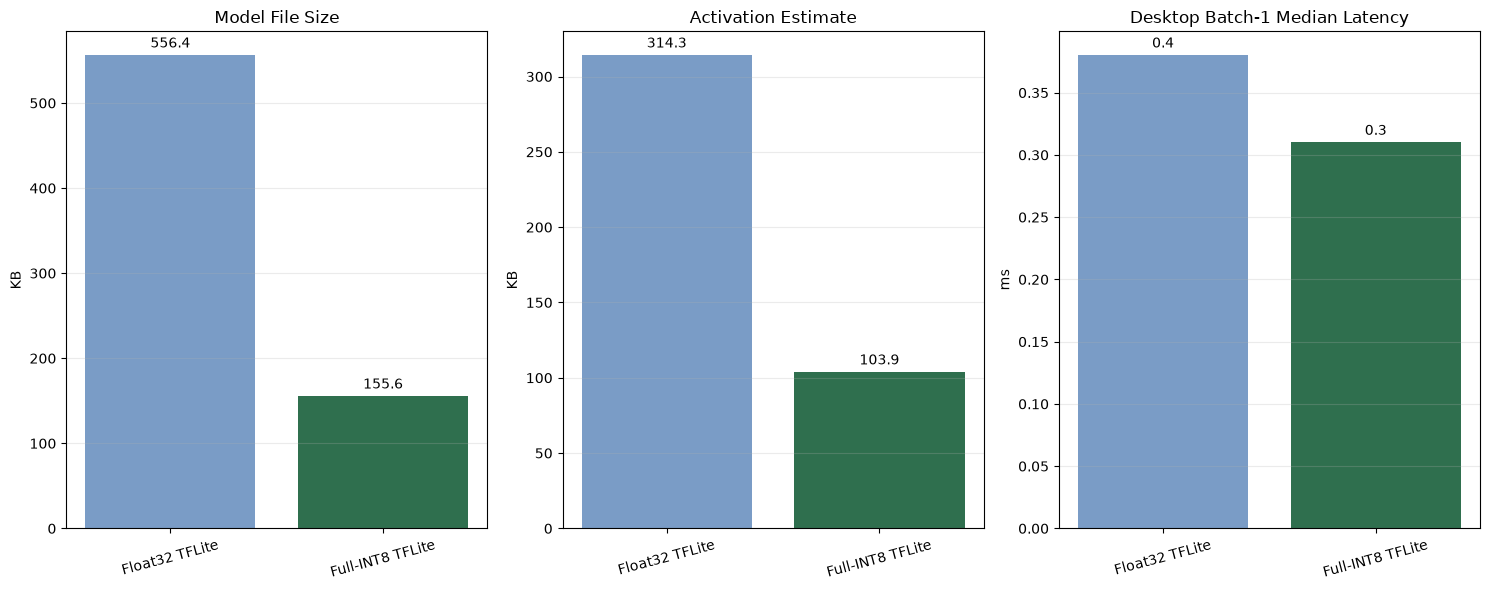

Saved: c:\Users\213053\OneDrive\Documenti\EEAI\src\outputs\edge_audit\v11_edge_audit_summary.json


In [8]:
labels = ["Float32 TFLite", "Full-INT8 TFLite"]
sizes_kib = [float_audit["size_bytes"] / 1024, int8_audit["size_bytes"] / 1024]
arenas_kib = [float_audit["arena_bytes"] / 1024, int8_audit["arena_bytes"] / 1024]
latencies_ms = [float_latency["median_ms"], int8_latency["median_ms"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for axis, values, title, ylabel in zip(
    axes,
    (sizes_kib, arenas_kib, latencies_ms),
    ("Model File Size", "Activation Estimate", "Desktop Batch-1 Median Latency"),
    ("KB", "KB", "ms"),
):
    bars = axis.bar(labels, values, color=("#7a9cc6", "#2f6f4e"))
    axis.bar_label(bars, fmt="%.1f", padding=3)
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.tick_params(axis="x", rotation=15)
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
FIGURE_PATH = OUTPUT_DIR / "v11_float_vs_int8_edge_comparison.png"
fig.savefig(FIGURE_PATH, dpi=180, bbox_inches="tight")
plt.show()

summary = {
    "parameter_count": parameter_count,
    "limits": {
        "model_size_kib": MODEL_LIMIT_BYTES / 1024,
        "activation_arena_kib": ARENA_LIMIT_BYTES / 1024,
    },
    "float32": {**float_audit, "latency": float_latency},
    "full_int8": {**int8_audit, "latency": int8_latency},
    "preprocessing_memory_kib": {
        "no_reuse_conceptual": no_reuse_kib,
        "streaming_persistent": streaming_kib,
        "streaming_with_reusable_scratch": streaming_with_scratch_kib,
        "host_tracemalloc_peak": peak_bytes / 1024,
    },
    "notes": {
        "latency": "Desktop batch-1 measurement; not ESP32-S3 latency.",
        "preprocessing": "Streaming value is a design estimate requiring explicit C/C++ buffer reuse.",
    },
}
SUMMARY_PATH.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved:", SUMMARY_PATH)

## 8. Conclusions for the report

- V11 uses **140,540 parameters** and a full-INT8 TFLite deployment model.
- Full INT8 reduces the TFLite file from **556.4 KB to 155.6 KB**, a 72.0% reduction, and leaves substantial margin below the 800 KB Flash limit.
- Quantization reduces the official-style activation estimate from **415.5 KB to 103.9 KB**. The float model would exceed the 300 KB constraint, whereas the INT8 model leaves 196.1 KB of model-arena margin.
- The graph contains only standard TFLite operations and no recurrent, CUSTOM, or Flex operations.
- The conservative batch-1 streaming design estimate is **255.8 KB**, including the model arena and reusable preprocessing scratch space, leaving approximately **44.2 KB** below 300 KB. This is a design estimate that must be verified in a production C/C++ implementation.
- The desktop script may batch frames for evaluator throughput, but the embedded design is causal and can operate with batch 1.
- A batch-1 implementation must reuse preprocessing buffers and quantize channels directly into the model input; retaining all float intermediates simultaneously is not SRAM-efficient.
- In the verified host run, median batch-1 inference was 0.422 ms for float32 and 0.365 ms for INT8. These values demonstrate the relative pipeline behaviour but are not ESP32-S3 latency measurements and will vary across runs.
- Phase differences, EMA state, and previous-frame context provide temporal and angular information without unsupported recurrent layers.

These results support the Edge Optimization argument without claiming that desktop latency equals ESP32-S3 latency.